# Laboratory 4, Part B - Multiple Linear Regression

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

With several input features the model becomes
`target = intercept + w1 x feature1 + w2 x feature2 + ...`.
Two datasets are used: **house prices** (7 features) and the **housing.csv** table
(rooms, neighbourhood status, pupil-teacher ratio -> median home value).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def run_regression(df, target, title):
    """Split, fit, score and plot a multiple linear regression on `df`."""
    features = [col for col in df.columns if col != target]
    X, y = df[features], df[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression().fit(X_train, y_train)
    predicted = model.predict(X_test)

    # Standardised coefficients (features scaled to mean 0, std 1) make effect sizes comparable.
    scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
    coef_table = pd.DataFrame({
        "feature": features,
        "coefficient": model.coef_,
        "standardised": scaled[-1].coef_,
    }).sort_values("standardised", key=abs, ascending=False).reset_index(drop=True)

    baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
    results = {
        "rows": len(df),
        "train_r2": model.score(X_train, y_train),
        "test_r2": r2_score(y_test, predicted),
        "mae": mean_absolute_error(y_test, predicted),
        "rmse": float(np.sqrt(mean_squared_error(y_test, predicted))),
        "baseline_r2": r2_score(y_test, baseline.predict(X_test)),
        "cv_r2": cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2").mean(),
    }

    print(f"=== {title} ===")
    print("Rows:", results["rows"], "| train:", len(X_train), "| test:", len(X_test))
    print(f"Intercept: {model.intercept_:,.2f}")
    display(coef_table.round(3))
    print(f"Test  MAE : {results['mae']:,.2f}")
    print(f"Test  RMSE: {results['rmse']:,.2f}")
    print(f"Test  R2  : {results['test_r2']:.3f}   (train R2 {results['train_r2']:.3f}, 5-fold CV mean {results['cv_r2']:.3f})")
    print(f"Always-predict-the-mean baseline R2: {results['baseline_r2']:.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(y_test, predicted, alpha=0.6, color="steelblue")
    low, high = min(y_test.min(), predicted.min()), max(y_test.max(), predicted.max())
    axes[0].plot([low, high], [low, high], color="black", linewidth=1)
    axes[0].set(title=f"{title}: actual vs predicted", xlabel="Actual", ylabel="Predicted")
    axes[1].hist(y_test.values - predicted, bins=20, color="darkorange", edgecolor="white")
    axes[1].set(title="Residuals (actual - predicted)", xlabel="Residual", ylabel="Count")
    plt.tight_layout()
    plt.show()
    return results, coef_table

## Dataset 1 - House prices

In [2]:
houses = pd.read_csv("data/house_price_regression_dataset.csv")
print("Shape:", houses.shape, "| missing values:", int(houses.isnull().sum().sum()))
display(houses.head())
print("Correlation of each feature with House_Price:")
print(houses.corr()["House_Price"].drop("House_Price").sort_values(ascending=False).round(3).to_string())

Shape: (1000, 8) | missing values: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Correlation of each feature with House_Price:
Square_Footage          0.991
Lot_Size                0.160
Garage_Size             0.052
Year_Built              0.052
Num_Bedrooms            0.015
Num_Bathrooms          -0.002
Neighborhood_Quality   -0.008


=== House price ===
Rows: 1000 | train: 800 | test: 200
Intercept: -2,010,567.42


,feature,coefficient,standardised
0,Square_Footage,199.513,249787.915
1,Year_Built,993.537,20662.122
2,Lot_Size,14885.384,19088.111
3,Num_Bedrooms,10225.204,14524.734
4,Num_Bathrooms,8208.435,6695.907
5,Garage_Size,5146.148,4219.449
6,Neighborhood_Quality,115.069,335.247


Test  MAE : 8,174.58
Test  RMSE: 10,071.48
Test  R2  : 0.998   (train R2 0.999, 5-fold CV mean 0.998)
Always-predict-the-mean baseline R2: -0.000


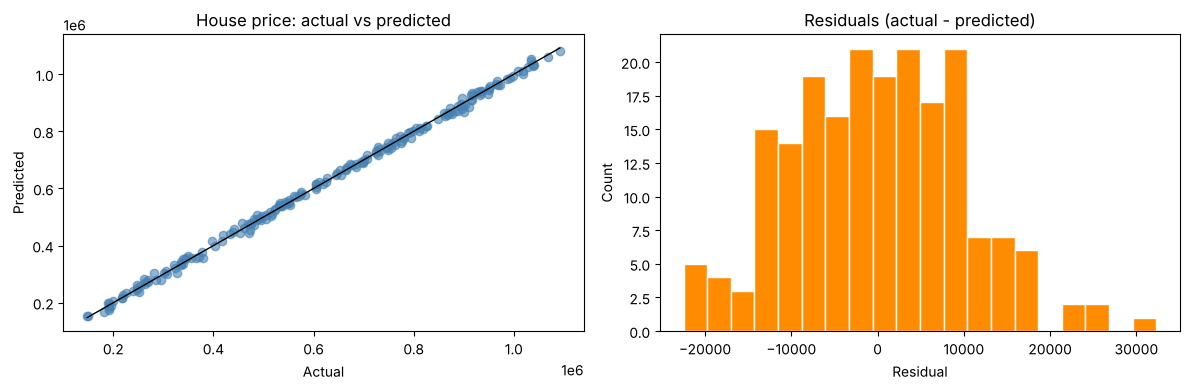

In [3]:
house_results, house_coefs = run_regression(houses, "House_Price", "House price")

In [4]:
top = house_coefs.iloc[0]
print("Strongest effect once features are on the same scale:", top["feature"])
print("Weakest effect:", house_coefs.iloc[-1]["feature"])
print()
sqft = house_coefs.set_index("feature").loc["Square_Footage", "coefficient"]
print(f"Reading one coefficient: with everything else fixed, each extra square foot adds about {sqft:,.0f} to the predicted price.")

Strongest effect once features are on the same scale: Square_Footage
Weakest effect: Neighborhood_Quality

Reading one coefficient: with everything else fixed, each extra square foot adds about 200 to the predicted price.


## Dataset 2 - housing.csv (RM, LSTAT, PTRATIO -> MEDV)

In [5]:
homes = pd.read_csv("data/housing.csv")
print("Shape:", homes.shape, "| missing values:", int(homes.isnull().sum().sum()))
display(homes.describe().round(2))
print("Correlation of each feature with MEDV:")
print(homes.corr()["MEDV"].drop("MEDV").sort_values(ascending=False).round(3).to_string())

Shape: (489, 4) | missing values: 0


,RM,LSTAT,PTRATIO,MEDV
count,489.00,489.00,489.00,489.00
mean,6.24,12.94,18.52,454342.94
std,0.64,7.08,2.11,165340.28
min,3.56,1.98,12.60,105000.00
25%,5.88,7.37,17.40,350700.00
50%,6.18,11.69,19.10,438900.00
75%,6.58,17.12,20.20,518700.00
max,8.40,37.97,22.00,1024800.00


Correlation of each feature with MEDV:
RM         0.697
PTRATIO   -0.519
LSTAT     -0.761


=== Median home value (MEDV) ===
Rows: 489 | train: 391 | test: 98
Intercept: 408,027.65


,feature,coefficient,standardised
0,LSTAT,-10620.637,-75604.397
1,RM,87322.204,58790.171
2,PTRATIO,-19324.410,-42110.893


Test  MAE : 64,277.29
Test  RMSE: 82,395.54
Test  R2  : 0.691   (train R2 0.719, 5-fold CV mean 0.705)
Always-predict-the-mean baseline R2: -0.062


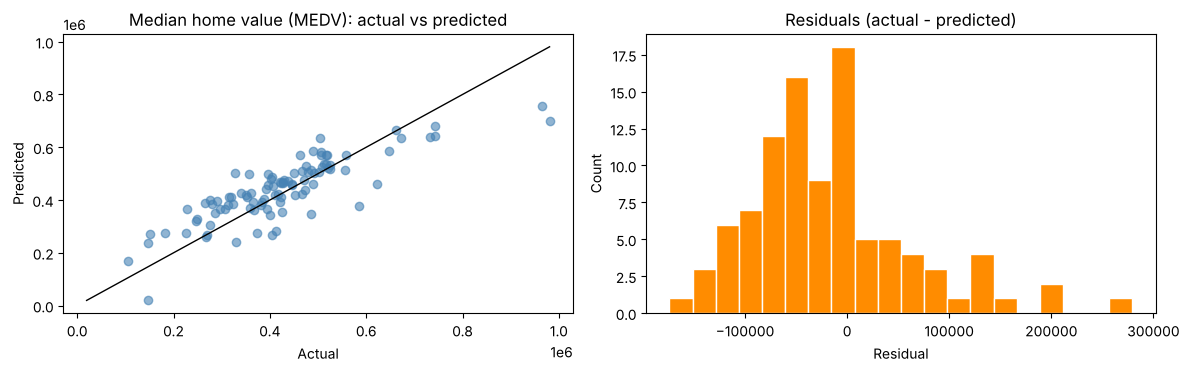

In [6]:
home_results, home_coefs = run_regression(homes, "MEDV", "Median home value (MEDV)")

In [7]:
rm = home_coefs.set_index("feature").loc["RM", "coefficient"]
lstat = home_coefs.set_index("feature").loc["LSTAT", "coefficient"]
print(f"More rooms (RM) raise the predicted value by about {rm:,.0f} per room; a higher LSTAT (percent lower-status residents) changes it by {lstat:,.0f} per point.")

More rooms (RM) raise the predicted value by about 87,322 per room; a higher LSTAT (percent lower-status residents) changes it by -10,621 per point.


## Side by side

In [8]:
summary = pd.DataFrame({"House price": house_results, "housing.csv": home_results}).T
summary = summary[["rows", "test_r2", "train_r2", "cv_r2", "baseline_r2", "mae", "rmse"]]
summary.round(3)

,rows,test_r2,train_r2,cv_r2,baseline_r2,mae,rmse
House price,1000.0,0.998,0.999,0.998,-0.000,8174.584,10071.484
housing.csv,489.0,0.691,0.719,0.705,-0.062,64277.289,82395.543


## Takeaways

Both models beat the always-predict-the-mean baseline by a wide margin when R squared is compared, and
the gap between training and test R squared shows whether either one is overfitting. Coefficients
in their original units cannot be ranked against each other because the features live on very
different scales (square feet vs a 1-10 quality score), which is why standardised coefficients are
shown too. A linear model assumes each feature acts additively and in a straight line; the residual
plots are the quick check of how well that holds.